In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

from scipy.stats import linregress, ks_2samp

import json
import sys
from pathlib import Path

In [2]:
sys.path.append(str(Path.cwd().parent))

from src.config import target

In [3]:
df = pd.read_csv("../data/raw/combined_gee_pm25.csv")

df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

df = df.dropna(subset=["date"]).copy()

print("Dataset shape:", df.shape)
print(
    "Date range:",
    df["date"].min(),
    "to",
    df["date"].max()
)

Dataset shape: (41718, 15)
Date range: 2016-11-25 00:00:00 to 2026-04-06 00:00:00


In [4]:
df = df.sort_values(
    ["sensor_name", "date"]
).reset_index(drop=True)

print("\nTimestamp quality")

print("Missing dates:", df["date"].isna().sum())

print(
    "Duplicate sensor-date pairs:",
    df.duplicated(
        subset=["sensor_name", "date"]
    ).sum()
)


Timestamp quality
Missing dates: 0
Duplicate sensor-date pairs: 2


In [5]:
daily_series = (
    df.groupby([
        "sensor_name",
        pd.Grouper(key="date", freq="D")
    ])[target]
    .median()
    .reset_index()
)

daily_series = daily_series.dropna(
    subset=[target]
)

print(daily_series.head())
print("Number of daily observations:", len(daily_series))

            sensor_name       date       pm25
0                  064F 2022-04-04   0.000000
1  AIX CENTRE ECOLE ART 2024-01-31  16.308696
2  AIX CENTRE ECOLE ART 2024-02-03  12.254167
3  AIX CENTRE ECOLE ART 2024-02-05  20.750000
4  AIX CENTRE ECOLE ART 2024-02-11   2.879167
Number of daily observations: 41716


In [6]:
top_sensor = (
    daily_series["sensor_name"]
    .value_counts()
    .index[0]
)

sensor_data = (
    daily_series[
        daily_series["sensor_name"] == top_sensor
    ]
    .sort_values("date")
)

series = sensor_data[target].dropna()

print("Selected sensor:", top_sensor)
print("Number of observations:", len(series))

Selected sensor: CENMO1
Number of observations: 1047


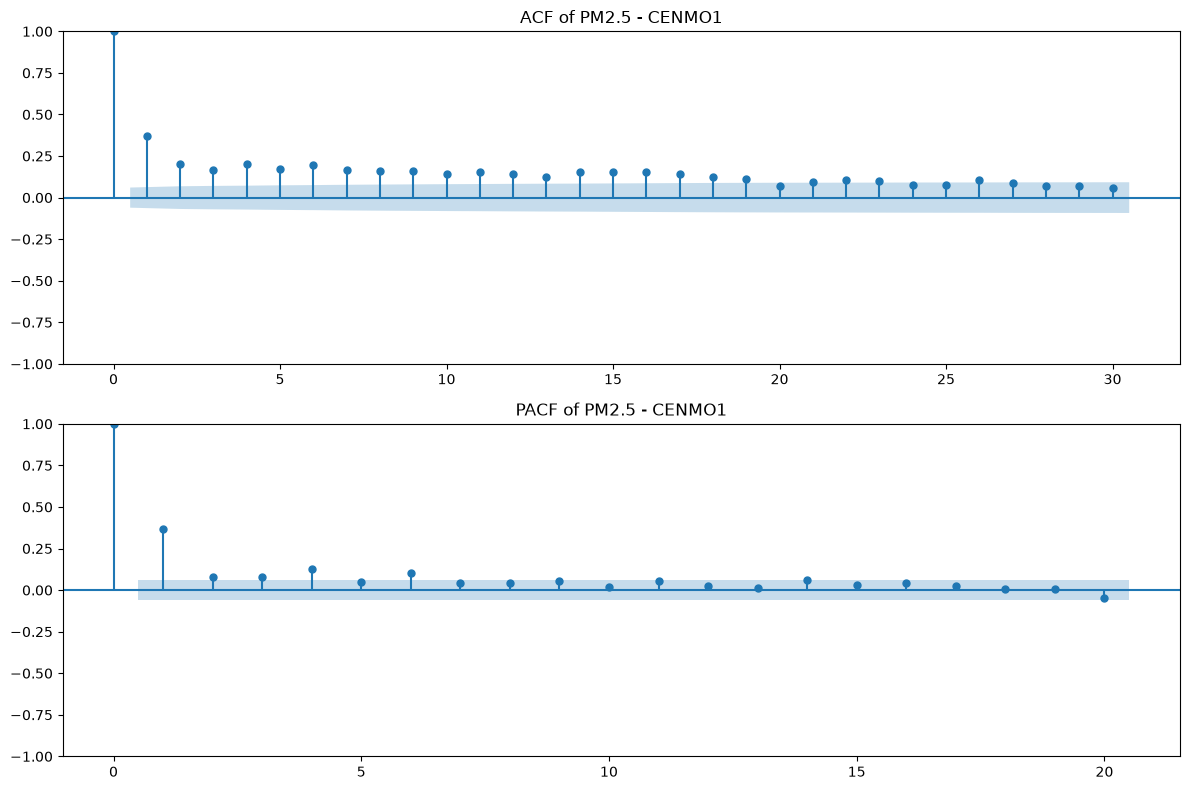

In [7]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8)
)

plot_acf(
    series,
    lags=min(30, len(series) - 1),
    ax=axes[0]
)

axes[0].set_title(
    f"ACF of PM2.5 - {top_sensor}"
)

plot_pacf(
    series,
    lags=min(20, len(series) // 2 - 1),
    ax=axes[1],
    method="ywm"
)

axes[1].set_title(
    f"PACF of PM2.5 - {top_sensor}"
)

plt.tight_layout()
plt.show()

In [8]:
adf_result = adfuller(series)

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))

if adf_result[1] < 0.05:
    print(
        "The series is stationary "
        "(p-value < 0.05)."
    )
else:
    print(
        "The series may not be stationary "
        "(p-value >= 0.05)."
    )

ADF Statistic: -6.8203
p-value: 0.0
The series is stationary (p-value < 0.05).


/var/folders/th/59x1dr0x3jqdmpq8vh9p081m0000gn/T/ipykernel_49308/638784619.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)


In [9]:
adf_result = adfuller(series)

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))

if adf_result[1] < 0.05:
    print(
        "The series is stationary "
        "(p-value < 0.05)."
    )
else:
    print(
        "The series may not be stationary "
        "(p-value >= 0.05)."
    )

ADF Statistic: -6.8203
p-value: 0.0
The series is stationary (p-value < 0.05).


/var/folders/th/59x1dr0x3jqdmpq8vh9p081m0000gn/T/ipykernel_49308/638784619.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)


In [10]:
ljung_box = acorr_ljungbox(
    series,
    lags=[10],
    return_df=True
)

print(ljung_box)

if ljung_box["lb_pvalue"].iloc[0] < 0.05:
    print(
        "There is significant autocorrelation."
    )
else:
    print(
        "No significant autocorrelation was detected."
    )

       lb_stat     lb_pvalue
10  431.907688  1.505744e-86
There is significant autocorrelation.


Trend slope: 0.0012
Trend p-value: 0.007


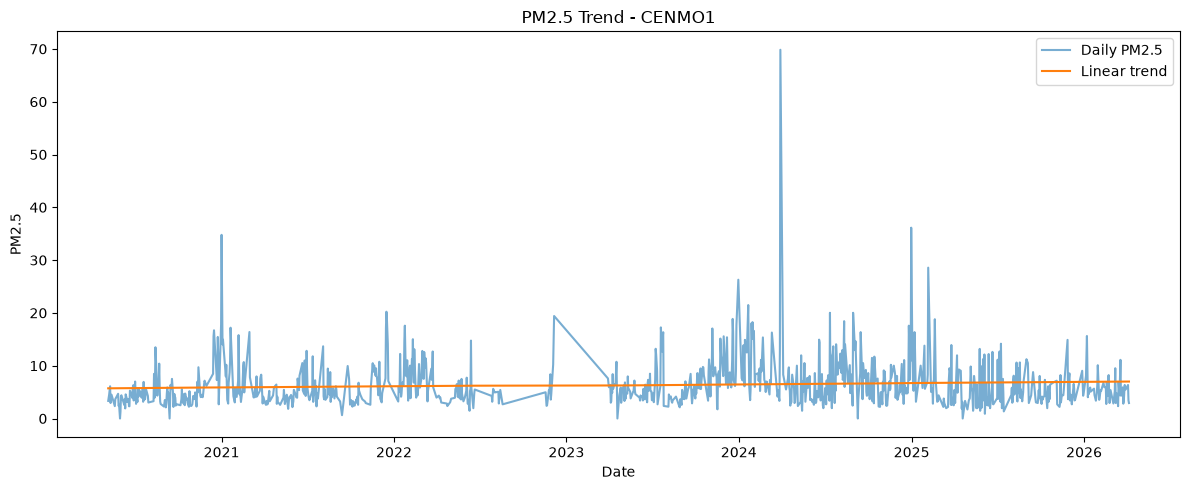

In [11]:
sensor_data = sensor_data.reset_index(
    drop=True
)

sensor_data["time_index"] = np.arange(
    len(sensor_data)
)

trend_result = linregress(
    sensor_data["time_index"],
    sensor_data[target]
)

print(
    "Trend slope:",
    round(trend_result.slope, 4)
)

print(
    "Trend p-value:",
    round(trend_result.pvalue, 4)
)

plt.figure(figsize=(12, 5))

plt.plot(
    sensor_data["date"],
    sensor_data[target],
    alpha=0.6,
    label="Daily PM2.5"
)

trend_line = (
    trend_result.intercept +
    trend_result.slope *
    sensor_data["time_index"]
)

plt.plot(
    sensor_data["date"],
    trend_line,
    label="Linear trend"
)

plt.title(
    f"PM2.5 Trend - {top_sensor}"
)

plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
df["month"] = df["date"].dt.month

monthly_stats = (
    df.groupby("month")[target]
    .agg(["count", "mean", "median", "std"])
)

print(monthly_stats.round(2))

       count   mean  median    std
month                             
1       3037  10.70    8.12  22.74
2       3117  11.26    9.25  11.13
3       2767   9.43    7.19   8.49
4       3131   7.34    6.16   8.16
5       3654   7.46    6.63   5.59
6       4162   9.07    7.79   5.91
7       4436   5.58    8.06  53.75
8       4568  10.31    8.98  18.29
9       3609   8.21    6.96  13.58
10      3056   9.00    7.76   8.00
11      3370  10.16    7.91  15.69
12      2811  12.37    8.88  35.54


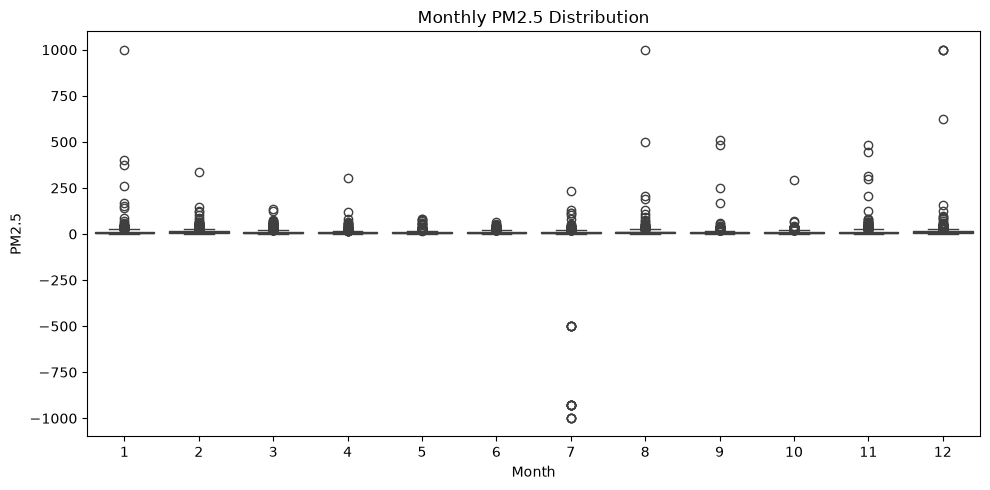

In [13]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="month",
    y=target
)

plt.title("Monthly PM2.5 Distribution")
plt.xlabel("Month")
plt.ylabel("PM2.5")

plt.tight_layout()
plt.show()

In [14]:
monthly_missing = (
    df.assign(month=df["date"].dt.month)
    .groupby("month")[target]
    .apply(lambda x: x.isna().mean() * 100)
)

print(
    "\nMissing PM2.5 percentage by month:"
)

print(monthly_missing.round(2))


Missing PM2.5 percentage by month:
month
1     0.0
2     0.0
3     0.0
4     0.0
5     0.0
6     0.0
7     0.0
8     0.0
9     0.0
10    0.0
11    0.0
12    0.0
Name: pm25, dtype: float64


In [15]:
lag_variables = [
    "AOD",
    "NO2",
    "CO",
    "O3"
]

lag_results = []

for sensor in df["sensor_name"].dropna().unique():

    sensor_df = (
        df[df["sensor_name"] == sensor]
        .sort_values("date")
        .copy()
    )

    for variable in lag_variables:

        if variable not in sensor_df.columns:
            continue

        sensor_df[f"{variable}_lag_1"] = (
            sensor_df[variable].shift(1)
        )

        correlation_data = sensor_df[
            [target, f"{variable}_lag_1"]
        ].dropna()

        if len(correlation_data) > 2:

            correlation = correlation_data[
                target
            ].corr(
                correlation_data[
                    f"{variable}_lag_1"
                ]
            )

            lag_results.append({
                "sensor_name": sensor,
                "variable": variable,
                "lag": 1,
                "correlation": correlation,
                "observations": len(
                    correlation_data
                )
            })

lead_lag_results = pd.DataFrame(
    lag_results
)

print(lead_lag_results.head())

            sensor_name variable  lag  correlation  observations
0  AIX CENTRE ECOLE ART      AOD    1     0.160327           457
1  AIX CENTRE ECOLE ART      NO2    1     0.158688           457
2  AIX CENTRE ECOLE ART       CO    1     0.168121           457
3  AIX CENTRE ECOLE ART       O3    1    -0.237222           457
4          AIX ROY RENE      AOD    1     0.456399           197
